SARIMA (Seasonal Autoregressive Integrated Moving Average)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
data_path = Path("../data/processed/RELIANCE_processed.csv")

df = pd.read_csv(data_path)

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

df.head()

,index,Date,Adj Close,Close,High,Low,Open,Volume,Target,lag1,lag2,lag3,lag5,lag10,Return,MA5,MA20,Volatility20
0,20,2015-01-30,194.951019,209.210754,212.868088,207.782104,212.582352,21746801,207.564957,212.445206,207.290649,203.221878,202.010391,197.553009,-0.015225,206.979782,200.206291,0.020023
1,21,2015-02-02,193.417374,207.564957,210.273666,207.027786,209.393616,19302710,214.319595,209.210754,212.445206,207.290649,202.730423,198.798798,-0.007867,207.946689,200.463448,0.020116
2,22,2015-02-03,199.711624,214.319595,215.062485,208.742157,208.742157,17092333,212.308060,207.564957,209.210754,212.445206,203.221878,201.073196,0.032542,210.166232,201.169199,0.021035
3,23,2015-02-04,197.837219,212.308060,215.736801,211.645172,214.662460,14072894,211.142288,214.319595,207.564957,209.210754,207.290649,206.422043,-0.009386,211.169714,202.228682,0.017932
4,24,2015-02-05,196.750900,211.142288,214.845322,209.747925,213.953857,12365643,207.987839,212.308060,214.319595,207.564957,212.445206,207.267792,-0.005491,210.909131,203.021866,0.017659


Create the time series

In [16]:
ts = df.set_index("Date")["Close"]

ts.head()

Date
2015-01-30    209.210754
2015-02-02    207.564957
2015-02-03    214.319595
2015-02-04    212.308060
2015-02-05    211.142288
Name: Close, dtype: float64

Train/test split

In [17]:
split = int(len(ts) * 0.8)

train = ts.iloc[:split]
test = ts.iloc[split:]

print("Training samples:", len(train))
print("Testing samples:", len(test))
print("Train range:", train.index.min(), "to", train.index.max())
print("Test range:", test.index.min(), "to", test.index.max())

Training samples: 2312
Testing samples: 578
Train range: 2015-01-30 00:00:00 to 2024-06-14 00:00:00
Test range: 2024-06-18 00:00:00 to 2026-10-07 00:00:00


Check stationarity with ADF test

In [18]:
result = adfuller(train)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] <= 0.05:
    print("Result: Stationary")
else:
    print("Result: Non-stationary")

ADF Statistic: -0.052404120149155596
p-value: 0.9539777127698936
Result: Non-stationary


/tmp/ipykernel_81419/1605092285.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(train)


First-order differencing

In [19]:
train_diff = train.diff().dropna()

result_diff = adfuller(train_diff)

print("ADF Statistic:", result_diff[0])
print("p-value:", result_diff[1])

if result_diff[1] <= 0.05:
    print("Result: Stationary")
else:
    print("Result: Non-stationary")

ADF Statistic: -29.163850304613852
p-value: 0.0
Result: Stationary


/tmp/ipykernel_81419/1616800664.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_diff = adfuller(train_diff)


ACF

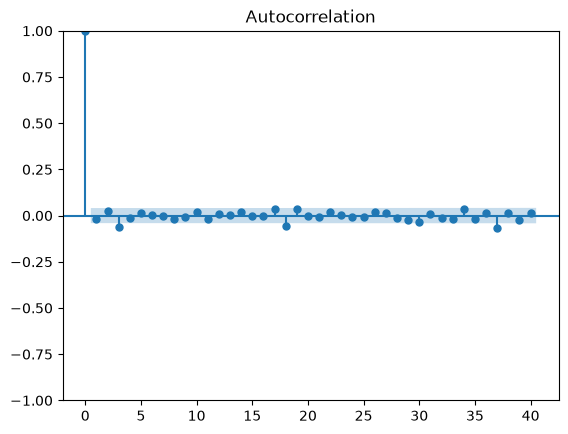

In [20]:
plot_acf(train_diff, lags=40)
plt.show()

PACF

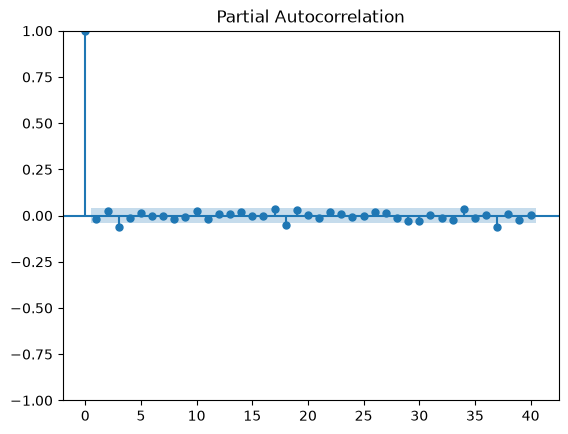

In [21]:
plot_pacf(train_diff, lags=40, method="ywm")
plt.show()

Sesonal AC

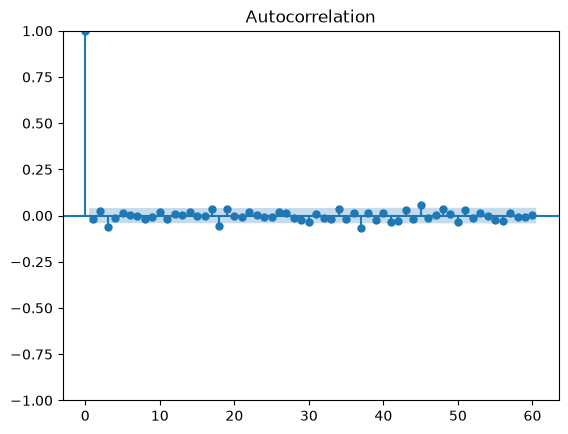

In [22]:
plot_acf(train_diff, lags=60)
plt.show()

Seasonal differencing

In [23]:
seasonal_diff = train.diff(5).dropna()

result_seasonal = adfuller(seasonal_diff, result_object=False)

print("ADF Statistic:", result_seasonal[0])
print("p-value:", result_seasonal[1])

if result_seasonal[1] <= 0.05:
    print("Seasonally differenced series: Stationary")
else:
    print("Seasonally differenced series: Non-stationary")

ADF Statistic: -8.889600316398147
p-value: 1.2529026939996106e-14
Seasonally differenced series: Stationary


First SARIMA Forecast

In [ ]:
train_model = train.reset_index(drop=True)

model = SARIMAX(
    train_model,
    order=(0, 1, 0),
    seasonal_order=(0, 0, 0, 5)
)

sarima_model = model.fit()

forecast = sarima_model.forecast(steps=len(test))

forecast = pd.Series(
    forecast.values,
    index=test.index
)

forecast.head()

Date
2024-06-18    1477.550049
2024-06-19    1477.550049
2024-06-20    1477.550049
2024-06-21    1477.550049
2024-06-24    1477.550049
dtype: float64

Evaluate SARIMA

In [28]:
mae_sarima = mean_absolute_error(test, forecast)
rmse_sarima = np.sqrt(mean_squared_error(test, forecast))

print("SARIMA MAE :", mae_sarima)
print("SARIMA RMSE:", rmse_sarima)

SARIMA MAE : 118.39665523119864
SARIMA RMSE: 143.05472274658513


Initial Observations:

1. Current SARIMA model is much worse than your Naive baseline.
2. For the entire multi-step test period, That's a problem for a long test horizon because the actual RELIANCE price can move substantially away from that fixed value.
3. Tune p and q for better results. 

Tuning p and q

In [29]:
orders = [
    (0, 1, 0),
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 0),
    (0, 1, 2),
    (2, 1, 1)
]

results = []

for order in orders:
    model = SARIMAX(
        train_model,
        order=order,
        seasonal_order=(0, 0, 0, 5)
    )
    
    fitted = model.fit(disp=False)
    
    results.append({
        "Order": order,
        "AIC": fitted.aic,
        "BIC": fitted.bic
    })

tuning_results = pd.DataFrame(results).sort_values("AIC")

tuning_results

/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,Order,AIC,BIC
0,"(0, 1, 0)",18515.924971,18521.670407
3,"(1, 1, 1)",18516.211414,18533.447721
6,"(2, 1, 1)",18516.761245,18539.742987
1,"(1, 1, 0)",18517.406678,18528.897549
2,"(0, 1, 1)",18517.431831,18528.922703
4,"(2, 1, 0)",18517.788922,18535.025229
5,"(0, 1, 2)",18517.947475,18535.183782


Evaluate the best candidates

In [30]:
candidate_orders = [
    (0, 1, 0),
    (1, 1, 1)
]

candidate_results = []

for order in candidate_orders:
    model = SARIMAX(
        train_model,
        order=order,
        seasonal_order=(0, 0, 0, 5)
    )
    
    fitted = model.fit(disp=False)
    
    forecast = fitted.forecast(steps=len(test))
    forecast = pd.Series(forecast.values, index=test.index)
    
    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))
    
    candidate_results.append({
        "Order": order,
        "AIC": fitted.aic,
        "MAE": mae,
        "RMSE": rmse
    })

candidate_results = pd.DataFrame(candidate_results)
candidate_results

/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,Order,AIC,MAE,RMSE
0,"(0, 1, 0)",18515.924971,118.396655,143.054723
1,"(1, 1, 1)",18516.211414,118.390768,143.047918


Tuning sesonal components

In [31]:
seasonal_orders = [
    (0, 0, 0, 5),
    (1, 0, 0, 5),
    (0, 0, 1, 5),
    (1, 0, 1, 5)
]

seasonal_results = []

for seasonal_order in seasonal_orders:
    model = SARIMAX(
        train_model,
        order=(1, 1, 1),
        seasonal_order=seasonal_order
    )
    
    fitted = model.fit(disp=False)
    
    forecast = fitted.forecast(steps=len(test))
    forecast = pd.Series(forecast.values, index=test.index)
    
    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))
    
    seasonal_results.append({
        "Seasonal Order": seasonal_order,
        "AIC": fitted.aic,
        "MAE": mae,
        "RMSE": rmse
    })

seasonal_results = pd.DataFrame(seasonal_results).sort_values("RMSE")

seasonal_results

/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/stat

,Seasonal Order,AIC,MAE,RMSE
0,"(0, 0, 0, 5)",18516.211414,118.390768,143.047918
2,"(0, 0, 1, 5)",18516.995649,118.600709,143.292021
1,"(1, 0, 0, 5)",18516.939436,118.626183,143.321722
3,"(1, 0, 1, 5)",18518.305954,119.046792,143.806234


Intermidiate Observations:

1. Best one till now is SARIMA(1,1,1)(0,0,0,5)
2. But this is still terrible compared with Naive.
3. There is no useful weekly seasonal pattern for this particular forecasting setup.

One-step-ahead forecasting

In [ ]:
rolling_predictions = []

history = train_model.copy()

for i in range(len(test)):
    model = SARIMAX(
        history,
        order=(1, 1, 1),
        seasonal_order=(0, 0, 0, 5)
    )
    
    fitted = model.fit(disp=False)

    prediction = fitted.forecast(steps=1).iloc[0]
    rolling_predictions.append(prediction)

    history = pd.concat([
        history,
        pd.Series([test.iloc[i]], index=[len(history)])
    ])

rolling_forecast = pd.Series(
    rolling_predictions,
    index=test.index
)

rolling_forecast.head()

/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/naksh/.local/lib/python3.14/site-packages/statsmodels/tsa/stat

Date
2024-06-18    1477.532840
2024-06-19    1480.934869
2024-06-20    1459.336289
2024-06-21    1472.781490
2024-06-24    1455.430499
dtype: float64

Evaluate rolling SARIMA

In [33]:
mae_rolling = mean_absolute_error(test, rolling_forecast)
rmse_rolling = np.sqrt(mean_squared_error(test, rolling_forecast))

print("Rolling SARIMA MAE :", mae_rolling)
print("Rolling SARIMA RMSE:", rmse_rolling)

Rolling SARIMA MAE : 13.363226683147804
Rolling SARIMA RMSE: 17.851297608863227


Final SARIMA using rolling forecasts

In [35]:
final_predictions = []
history = train_model.copy()

for i in range(len(test)):
    model = SARIMAX(
        history,
        order=(0, 1, 0),
        seasonal_order=(0, 0, 0, 5)
    )

    fitted = model.fit(disp=False)

    prediction = fitted.forecast(steps=1).iloc[0]
    final_predictions.append(prediction)

    history = pd.concat([
        history,
        pd.Series([test.iloc[i]], index=[len(history)])
    ])

sarima_forecast = pd.Series(
    final_predictions,
    index=test.index
)

sarima_forecast.head()

Date
2024-06-18    1477.550049
2024-06-19    1481.025024
2024-06-20    1458.650024
2024-06-21    1473.699951
2024-06-24    1454.199951
dtype: float64

Final SARIMA metrics

In [36]:
sarima_mae = mean_absolute_error(test, sarima_forecast)
sarima_rmse = np.sqrt(mean_squared_error(test, sarima_forecast))

print("Final SARIMA MAE :", sarima_mae)
print("Final SARIMA RMSE:", sarima_rmse)

Final SARIMA MAE : 13.35233378162846
Final SARIMA RMSE: 17.837061332445522


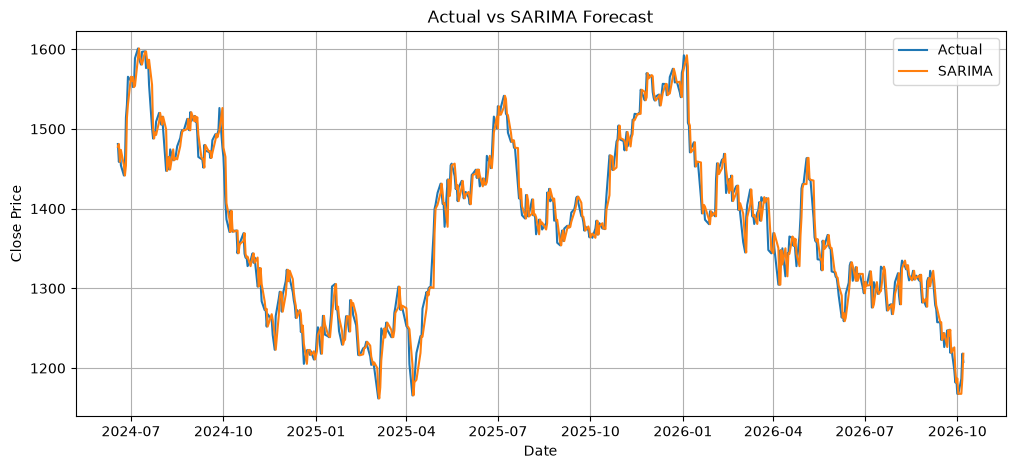

In [37]:
plt.figure(figsize=(12, 5))

plt.plot(test.index, test, label="Actual")
plt.plot(test.index, sarima_forecast, label="SARIMA")

plt.title("Actual vs SARIMA Forecast")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.grid(True)
plt.show()

Final Observations:

1) SARIMA(0,1,0)(0,0,0,5) achieved an MAE of 13.35 and RMSE of 17.84 using rolling one-step forecasting.
2. The model effectively captured short-term price movements, with predictions closely following the actual stock-price trend.
3. SARIMA outperformed Linear Regression but did not outperform the Naive baseline, which remained the best model.